# Adding coastlines to a map
Coastlines constitute an essential ingredients in most of the maps.     
The spatial resolution depend on the map extend, here we will present different ways to get increasingly fine coastlines.

In [1]:
using Makie
using CairoMakie
using GeoMakie
using NCDatasets
using JupyterFormatter
enable_autoformat()

1-element Vector{Function}:
 format_current_cell (generic function with 1 method)

## Preparing the plots
### Setting the region of interest
In this notebook we will focus on a rather small domain around Calvi (Corsica).

In [73]:
domain = [8.67615, 8.8417, 42.5372, 42.6268]

4-element Vector{Float64}:
  8.67615
  8.8417
 42.5372
 42.6268

### Setting the grid options

In [74]:
gridoptions = Dict(
    :limits => ((domain[1], domain[2]), (domain[3], domain[4])),
    :xgridstyle => :dash,
    :ygridstyle => :dash,
    :xgridcolor => :gray70,
    :ygridcolor => :gray70,
    :xticks => 8.6:0.05:8.9,
    :yticks => 42.5:0.025:43.0,
    :dest => "EPSG:3035",
    :titlesize => 20,
)

Dict{Symbol, Any} with 9 entries:
  :ygridcolor => :gray70
  :titlesize  => 20
  :xgridstyle => :dash
  :ygridstyle => :dash
  :dest       => "EPSG:3035"
  :xgridcolor => :gray70
  :xticks     => 8.6:0.05:8.9
  :yticks     => 42.5:0.025:43.0
  :limits     => ((8.67615, 8.8417), (42.5372, 42.6268))

## Natural Earth
With GeoMakie, one has access to built-in functions that easily load and plot map data from the [Natural Earth](https://www.naturalearthdata.com/) dataset.      
Three resolutions are available: 110 m (default), 50 m and 10m.

In [75]:
function plot_naturalearth_coast(
    domain::Vector{Float64},
    resolution::Int64 = 110,
    title::String = "",
)
    fig = Figure()
    ga = GeoAxis(fig[1, 1]; title = title, gridoptions...)
    lines!(ga, GeoMakie.coastlines(resolution))
    return fig
end

plot_naturalearth_coast (generic function with 3 methods)

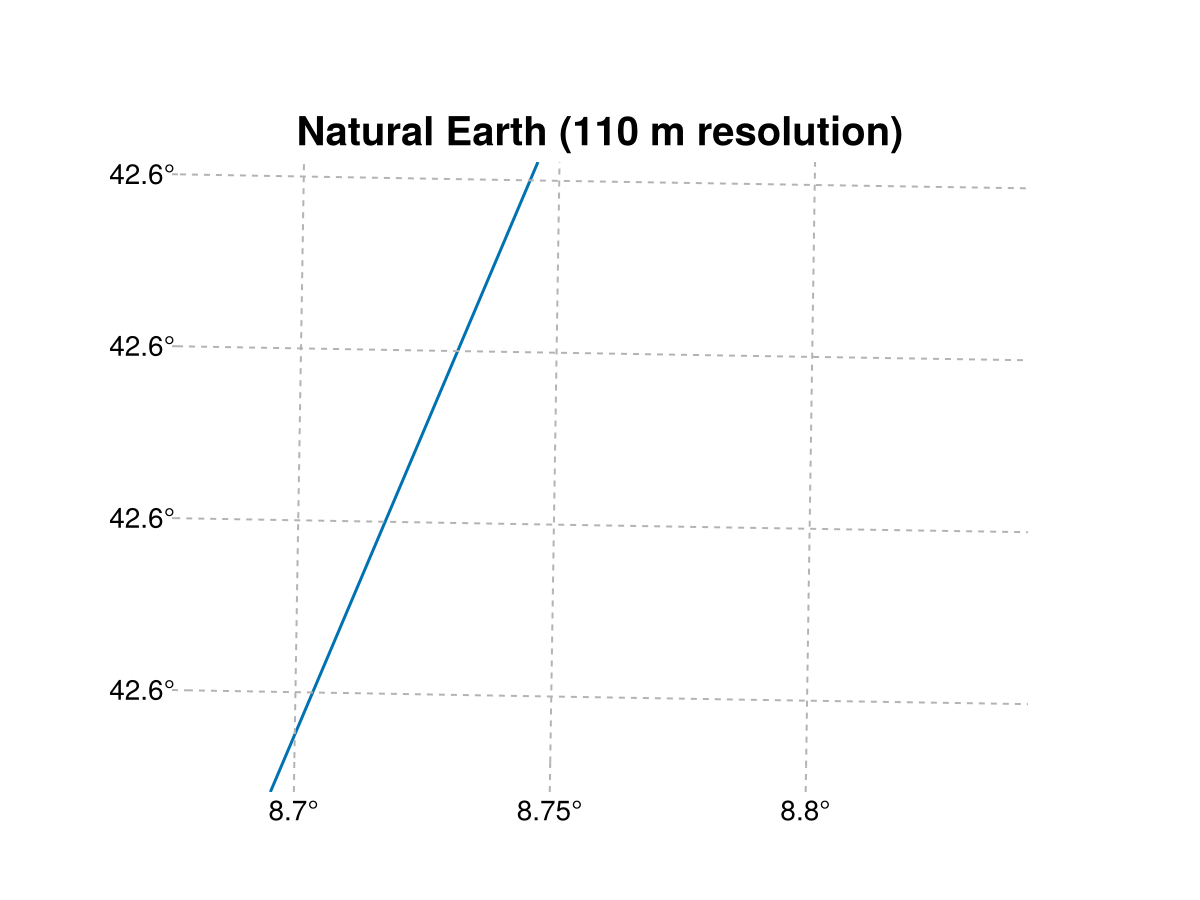

In [76]:
plot_naturalearth_coast(domain, 110, "Natural Earth (110 m resolution)")

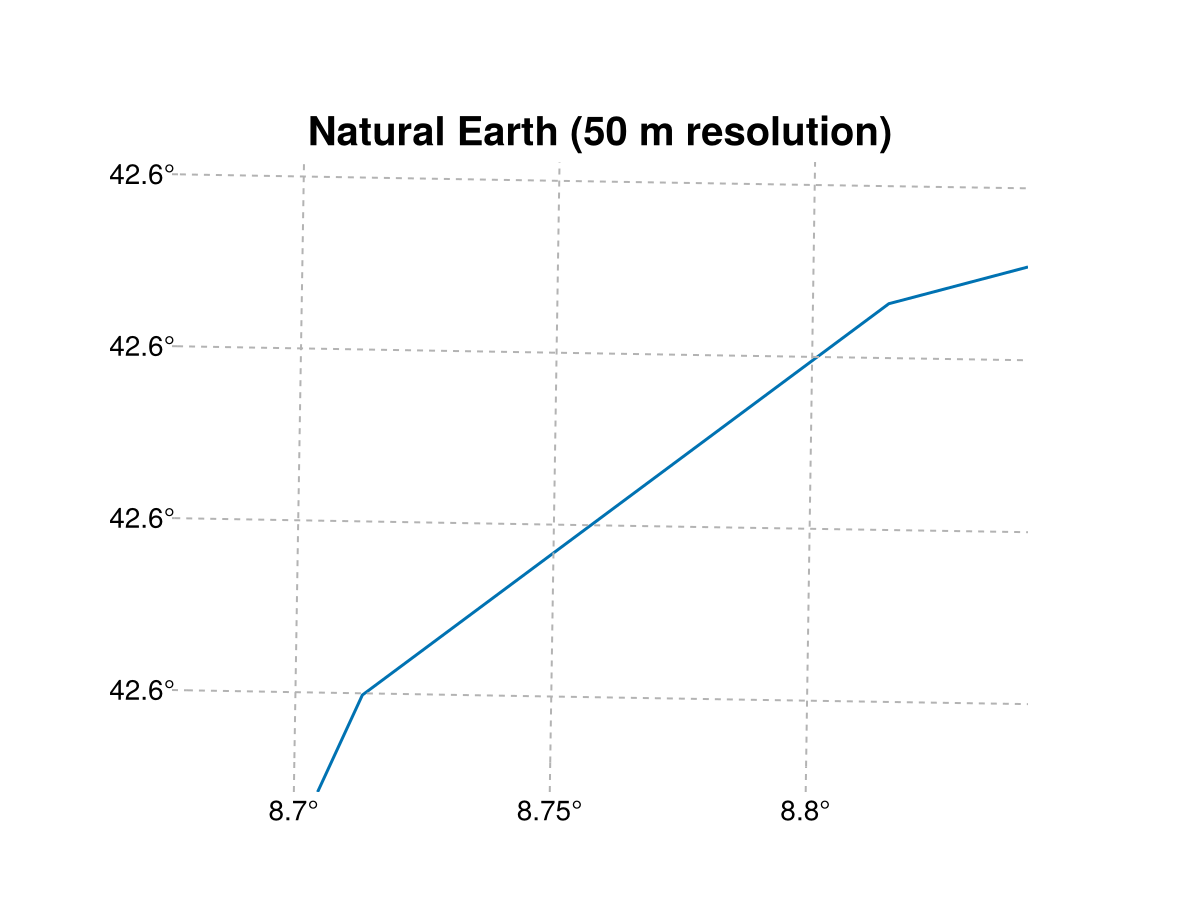

In [77]:
plot_naturalearth_coast(domain, 50, "Natural Earth (50 m resolution)")

Global Self-consistent, Hierarchical, High-resolution Geography Database

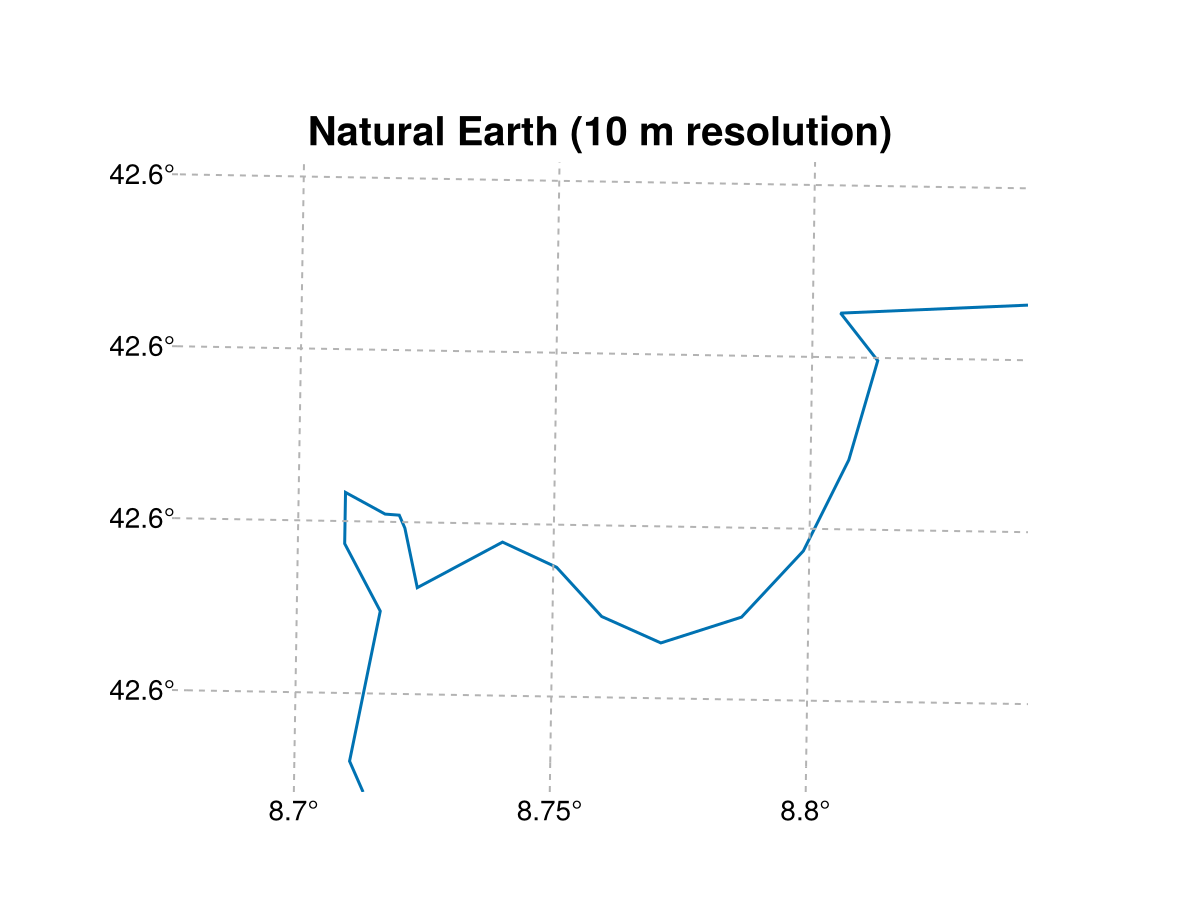

In [78]:
plot_naturalearth_coast(domain, 10, "Natural Earth (10 m resolution)")

## Global Self-consistent, Hierarchical, High-resolution Geography Database (GSHHG)
The dataset can be accessed using the [`GeoDatasets`](https://juliageo.org/GeoDatasets.jl) module.

In [79]:
using GeoDatasets

The geography data come in five resolutions:
1. full resolution,
2. high resolution,
3. intermediate resolution,
4. low resolution,
5. crude resolution.

The different resolutions are illustred in the next maps.     
Note that the coastline is again extracted only in the region of interest.

In [80]:
function extract_coast_gshhg(domain::Vector{Float64}, resolution::Char = 'l')

    subset_coastline = filter(
        seg -> begin
            lon, lat = seg
            # Check if any point falls within your region of interest
            any(
                (lon .>= domain[1]) .&
                (lon .<= domain[2]) .&
                (lat .>= domain[3]) .&
                (lat .<= domain[4]),
            )
        end,
        GeoDatasets.gshhg(resolution, 1),
    )
    return subset_coastline
end

extract_coast_gshhg (generic function with 2 methods)

In [81]:
function plot_gshhg_coast(
    domain::Vector{Float64},
    resolution::Char = 'l',
    title::String = "",
)

    subset_coastline = extract_coast_gshhg(domain, resolution)
    fig = Figure()
    ga = GeoAxis(fig[1, 1]; title = title, gridoptions...)

    for (loncoast, latcoast) in subset_coastline
        lines!(ga, loncoast, latcoast, color = :black)
    end
    return fig
end

plot_gshhg_coast (generic function with 3 methods)

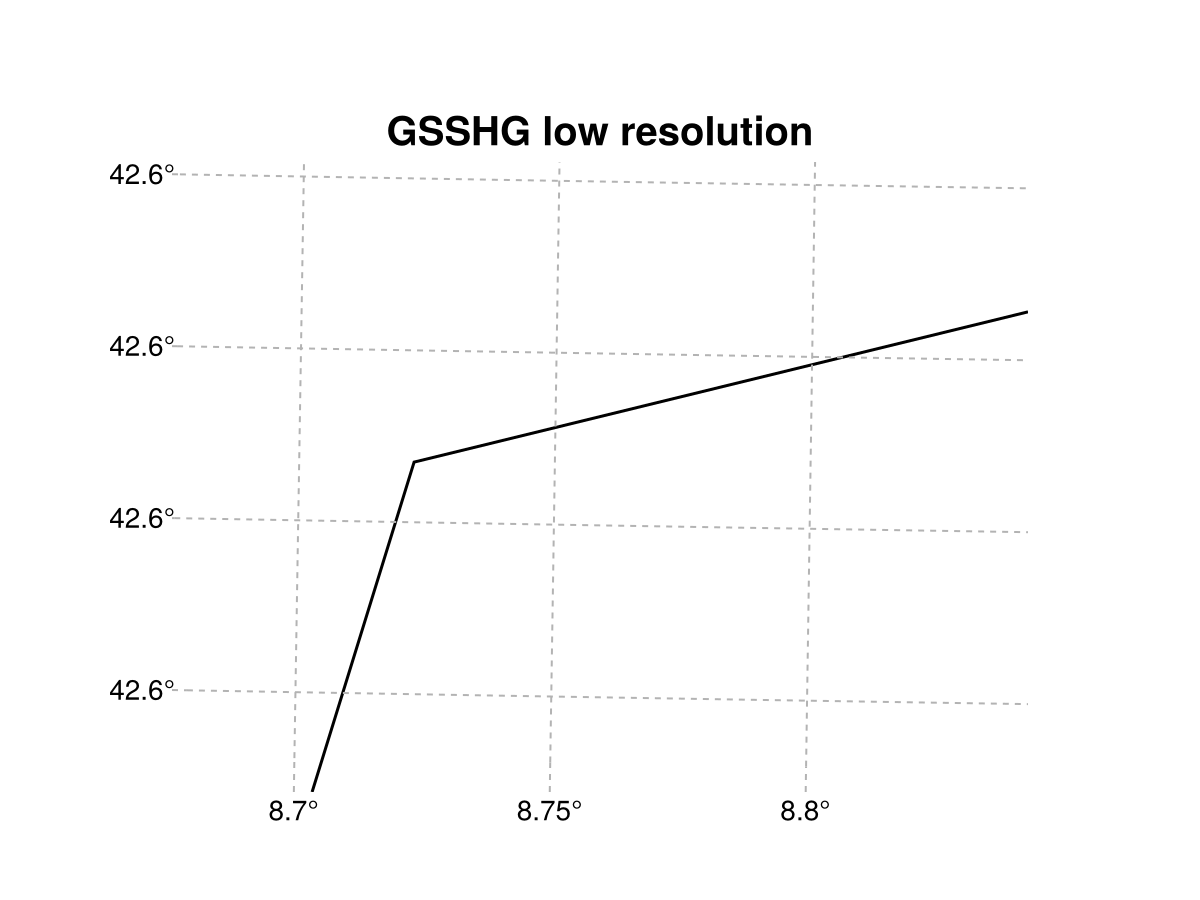

In [82]:
plot_gshhg_coast(domain, 'l', "GSSHG low resolution")

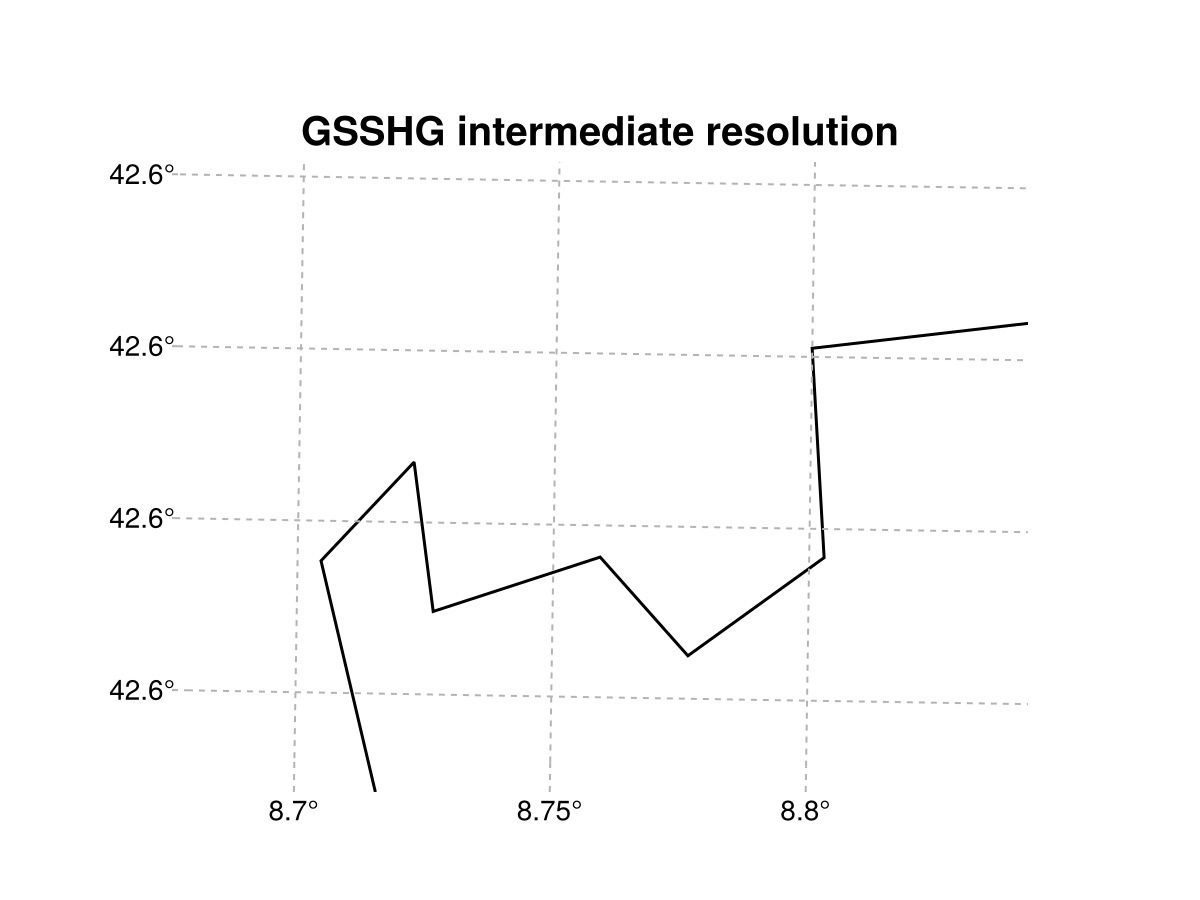

In [83]:
plot_gshhg_coast(domain, 'i', "GSSHG intermediate resolution")

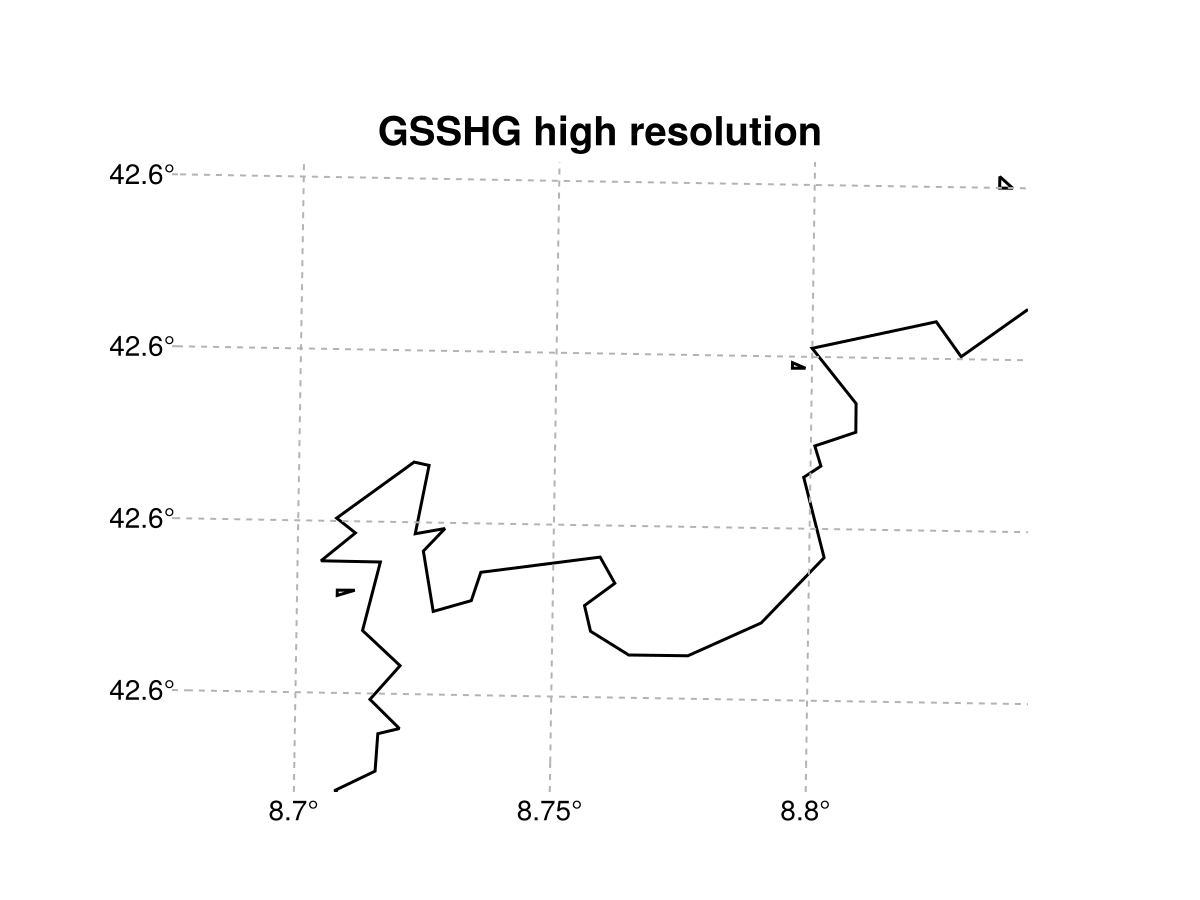

In [84]:
plot_gshhg_coast(domain, 'h', "GSSHG high resolution")

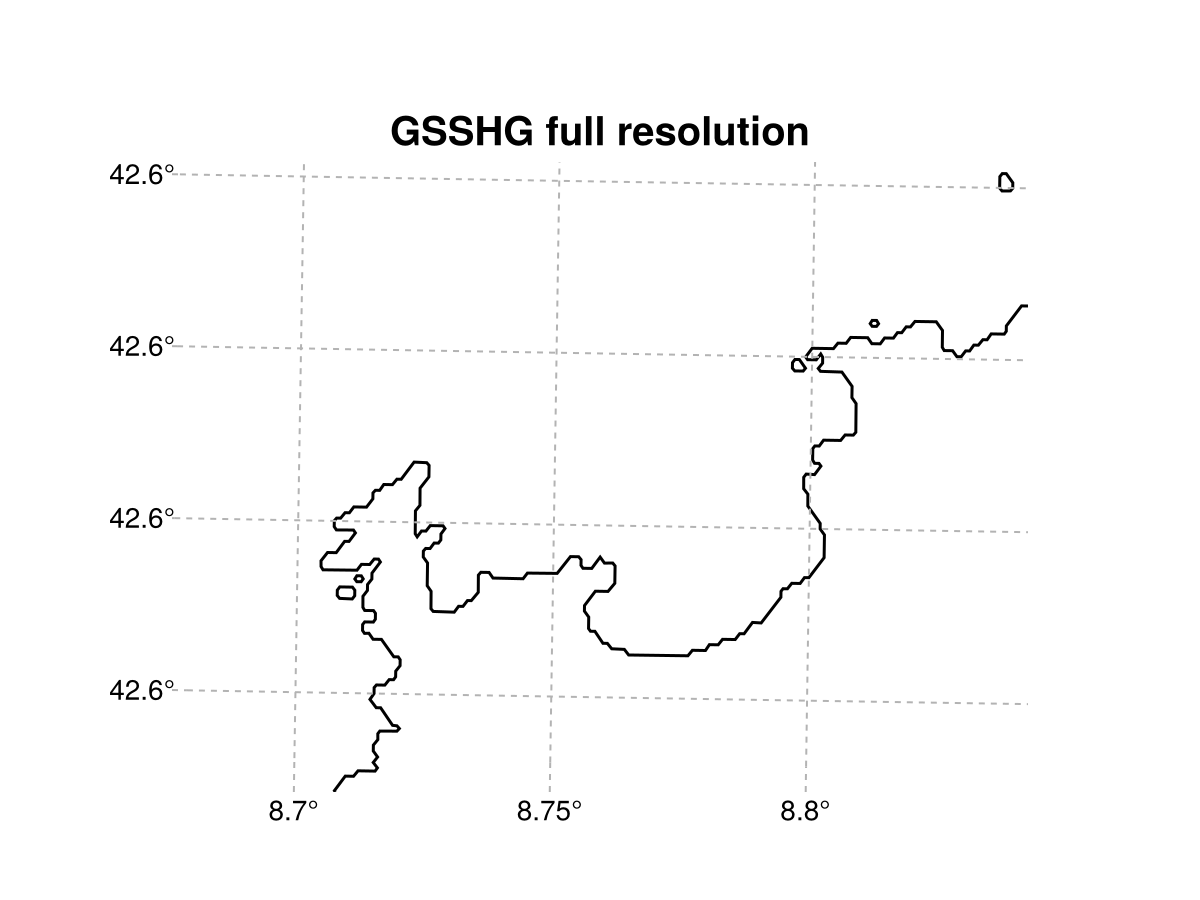

In [85]:
plot_gshhg_coast(domain, 'f', "GSSHG full resolution")

<div class="alert alert-block alert-info">
<b>Note: </b> even with the full resolution, the result is not good enough.
</div>

## EMODnet coastline
EMODnet, through its bathymetry component, provides a high-resolution coastline, available as a zip file containing a shape file:  
https://downloads.emodnet-bathymetry.eu/v11/EMODnet_Bathymetry_2022_coastlines.zip.     
After extraction of the archive, the shaper file can easily be open using the [`ShapeFile`](https://github.com/JuliaGeo/Shapefile.jl) module.

In [86]:
using Shapefile
using DataFrames
using GeoInterface

In order to perform a subsetting on the region of interest, the file is read as a table, which is then converted as a DataFrame object. Each geometry is checked against the domain of intest. 

In [87]:
table = Shapefile.Table("EMODnet_satellite_coastline_MSL.shp")
df = DataFrame(table)

subset_df = filter(
    row -> begin
        # Access the geometry column directly from the DataFrameRow
        geom = row.geometry

        # Retrieve the Minimum Bounding Rectangle (MBR)
        mbr = geom.MBR

        # Check if the polygon's bounding box fits inside your domain target coordinates
        return mbr.left <= domain[2] &&
               mbr.right >= domain[1] &&
               mbr.bottom <= domain[4] &&
               mbr.top >= domain[3]
    end,
    df,
);

#### Create the plot

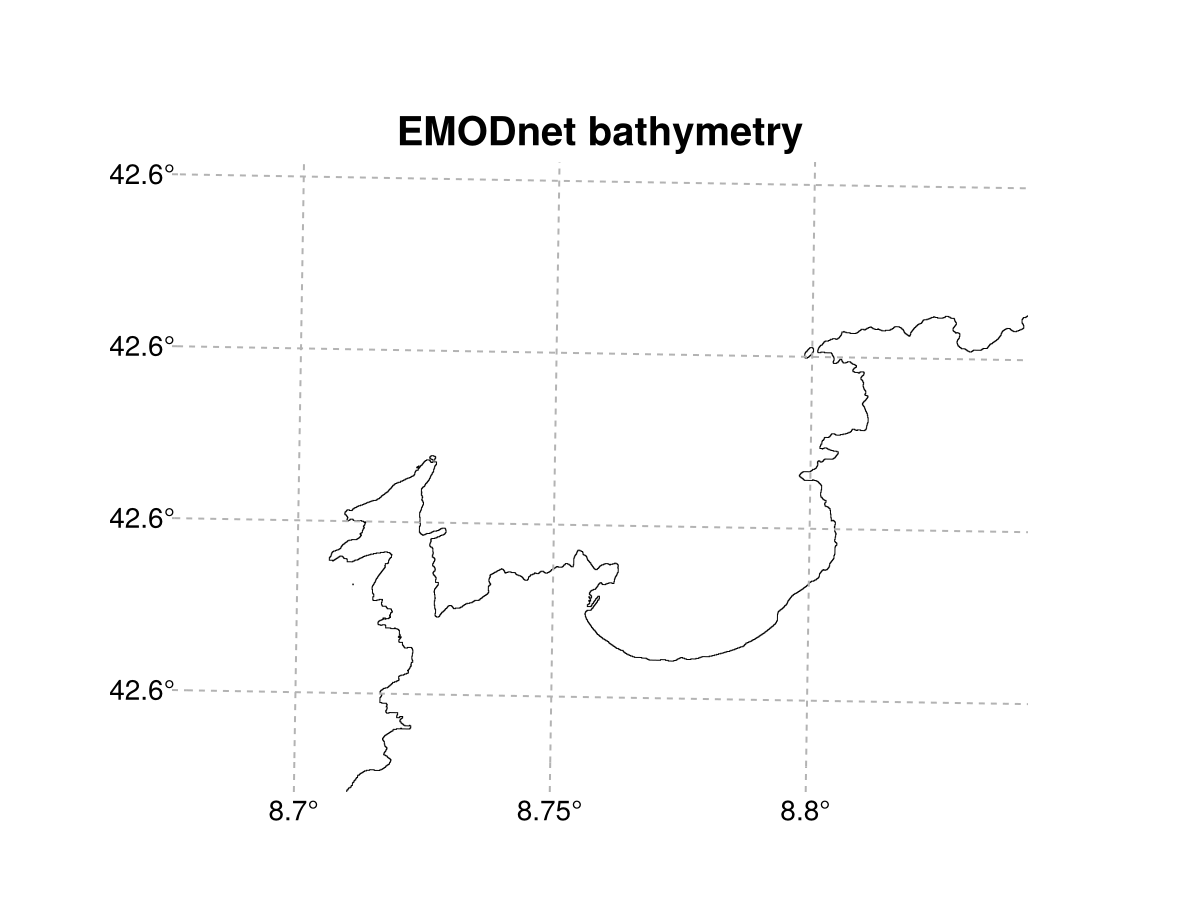

CairoMakie.Screen{IMAGE}


In [88]:
clean_polylines = collect(skipmissing(subset_df.geometry));

fig = Figure()
ga = GeoAxis(fig[1, 1]; title = "EMODnet bathymetry", gridoptions...)

for polyline in clean_polylines
    # Decompose geometry into its parts (nested arrays of coordinates)
    line_parts = GeoInterface.coordinates(polyline)

    for coord_sequence in line_parts
        # Convert the coordinate pairs into Makie Point2f format
        makie_points = [Point2f(coord[1], coord[2]) for coord in coord_sequence]

        # Plot this line segment
        lines!(ga, makie_points, color = :black, linewidth = 0.5)
    end
end
display(fig)

## Working with local datasets
When working on specific regions, it is sometimes recommended to download data from national institutes (for instance national geographical institutes) in order to obtained a sufficient resolution.